# Comprehensive Guide to Decision Trees for Production AI/ML Engineers

This notebook provides a job-ready, mathematically grounded, and highly practical guide to Decision Trees. As a future-proof AI/ML engineer, mastering decision trees is critical because they serve as the foundational building blocks for state-of-the-art ensemble models like Random Forests, GBDT, XGBoost, and LightGBM.

### What we will cover:
1. **Theoretical Foundations** (Entropy, Information Gain, Gini Impurity, and Variance Reduction)
2. **Synthetic Dataset Generation** (Simulating a real-world classification problem)
3. **Model Training & Visualization** (Visualizing how trees partition feature space)
4. **Hyperparameter Tuning & Pruning** (Preventing overfitting using pre-pruning techniques)
5. **Evaluation Metrics** (Going beyond accuracy to precision, recall, F1, and ROC-AUC)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Set random seed for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Synthetic Data Generation

To simulate a realistic task, we generate a synthetic binary classification dataset representing customer churn prediction (e.g., predicting whether a user will cancel a subscription). This dataset contains both highly informative features and noisy features.

In [ ]:
# Generate synthetic dataset
X, y = make_classification(
    n_samples=1000,
    n_features=5,
    n_informative=3,
    n_redundant=1,
    n_classes=2,
    weights=[0.7, 0.3], # Slightly imbalanced
    random_state=42
)

feature_names = ['Monthly_Usage_Hours', 'Support_Tickets', 'Subscription_Age_Months', 'Avg_Response_Time', 'Irrelevant_Noise_Feature']
df = pd.DataFrame(X, columns=feature_names)
df['Churn'] = y

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df[feature_names], df['Churn'], test_size=0.2, random_state=42, stratify=df['Churn']
)

print(f"Training Set Size: {X_train.shape[0]} samples")
print(f"Test Set Size: {X_test.shape[0]} samples")
display(df.head())

Training Set Size: 800 samples
Test Set Size: 200 samples


,Monthly_Usage_Hours,Support_Tickets,Subscription_Age_Months,Avg_Response_Time,Irrelevant_Noise_Feature,Churn
0,-0.038769,-0.649239,-0.224746,-1.346275,0.126879,0
1,1.005284,-1.373239,1.157346,0.126493,1.422799,0
2,-0.742455,-0.573257,1.688442,-2.588237,0.762562,0
3,-1.587158,1.758582,-0.930664,0.764614,2.415399,1
4,-0.941758,0.367913,-0.549360,-2.029919,-1.503957,0


## 2. Training an Overfitted Decision Tree

By default, Decision Trees grow until all leaves are pure (meaning they overfit the training data). Let's train an unconstrained decision tree to visualize this behavior.

In [ ]:
# Initialize an unconstrained decision tree classifier
overfitted_tree = DecisionTreeClassifier(random_state=42)
overfitted_tree.fit(X_train, y_train)

train_acc = overfitted_tree.score(X_train, y_train)
test_acc = overfitted_tree.score(X_test, y_test)

print(f"Unconstrained Tree Training Accuracy: {train_acc * 100:.2f}%")
print(f"Unconstrained Tree Testing Accuracy: {test_acc * 100:.2f}%")
print(f"Tree Depth: {overfitted_tree.get_depth()}")

Unconstrained Tree Training Accuracy: 100.00%
Unconstrained Tree Testing Accuracy: 92.00%
Tree Depth: 11


## 3. Pruning and Hyperparameter Tuning

To build a robust model, we must apply regularization (pre-pruning) by tuning parameters like `max_depth`, `min_samples_split`, and `min_samples_leaf`.

In [ ]:
# Initialize a regularized (pruned) decision tree classifier
pruned_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)
pruned_tree.fit(X_train, y_train)

pruned_train_acc = pruned_tree.score(X_train, y_train)
pruned_test_acc = pruned_tree.score(X_test, y_test)

print(f"Pruned Tree Training Accuracy: {pruned_train_acc * 100:.2f}%")
print(f"Pruned Tree Testing Accuracy: {pruned_test_acc * 100:.2f}%")

Pruned Tree Training Accuracy: 95.38%
Pruned Tree Testing Accuracy: 91.50%


## 4. Visualizing the Decision Tree and Feature Importances

Let's visualize the pruned decision tree structure and evaluate which features contributed most to its splits.

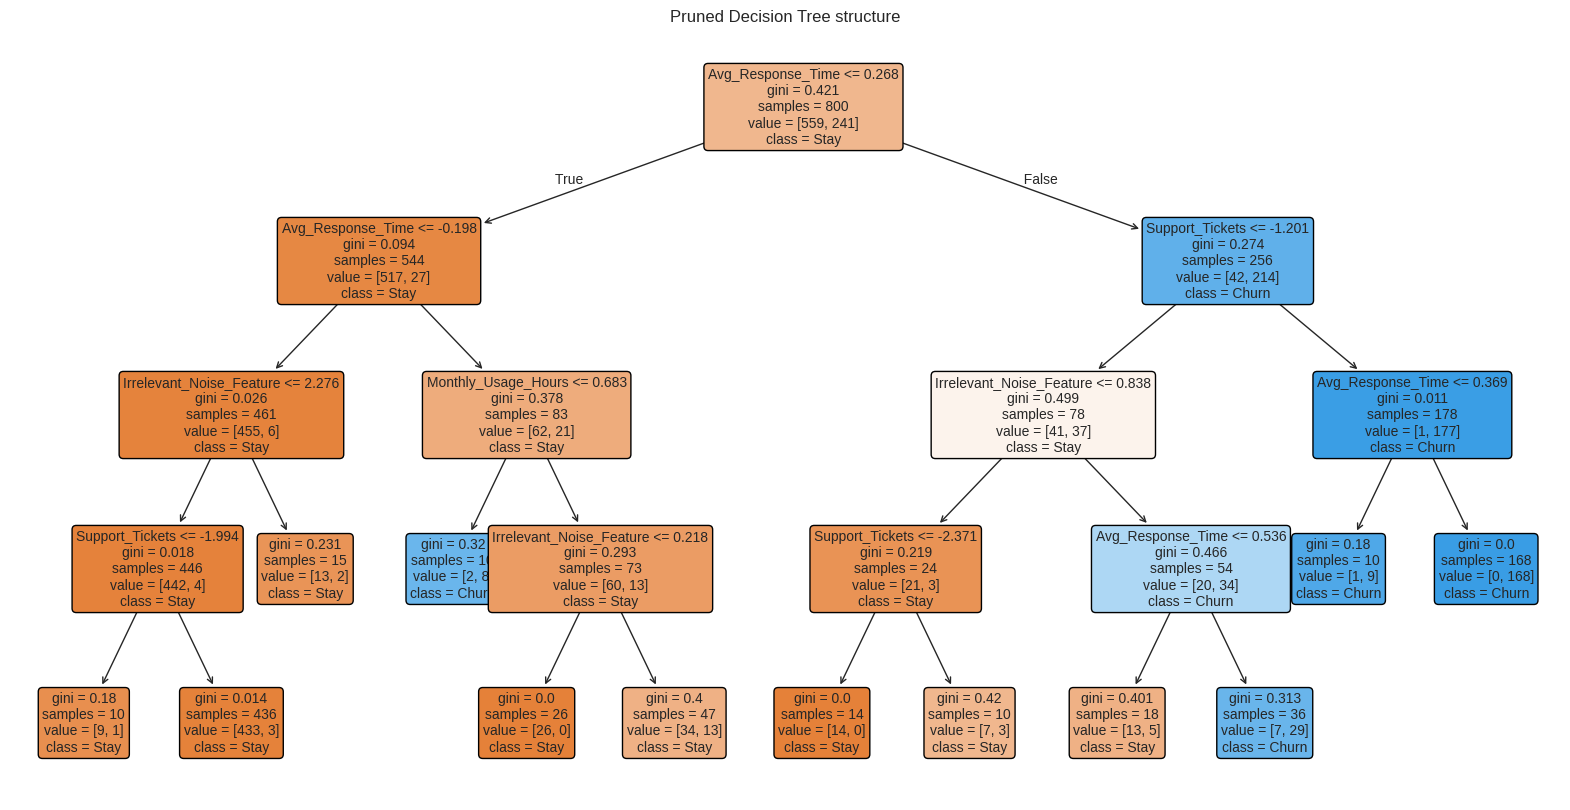

In [ ]:
# Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(
    pruned_tree,
    feature_names=feature_names,
    class_names=['Stay', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Pruned Decision Tree structure")
plt.show()

/tmp/ipykernel_1405/782445631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette='viridis')


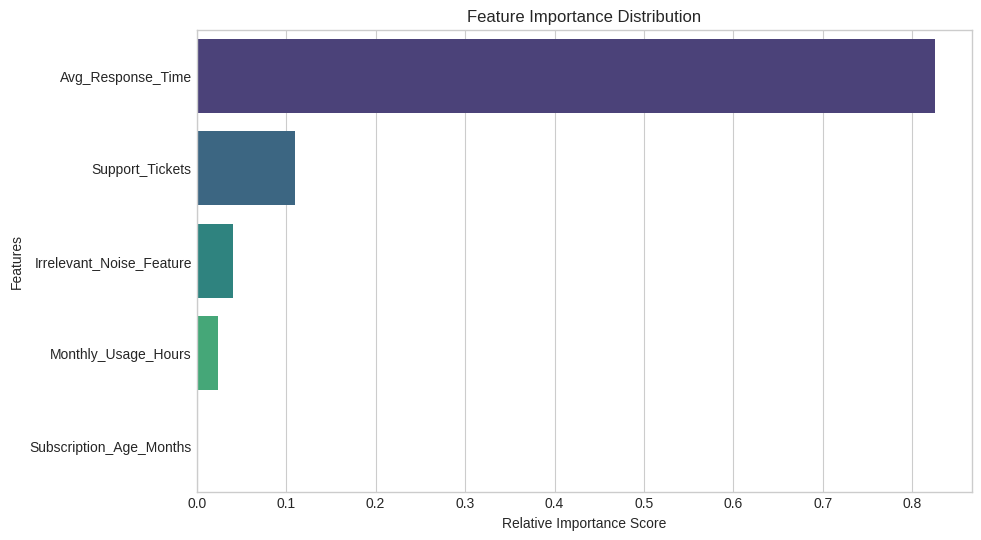

In [ ]:
# Plot Feature Importances
importances = pruned_tree.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette='viridis')
plt.title("Feature Importance Distribution")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.show()

## 5. Model Evaluation Metrics

As a professional engineer, you must evaluate classification models using confusion matrices, classification reports (Precision, Recall, F1-Score), and ROC-AUC curves.

Classification Report:

              precision    recall  f1-score   support

        Stay       0.93      0.95      0.94       140
       Churn       0.88      0.83      0.85        60

    accuracy                           0.92       200
   macro avg       0.90      0.89      0.90       200
weighted avg       0.91      0.92      0.91       200



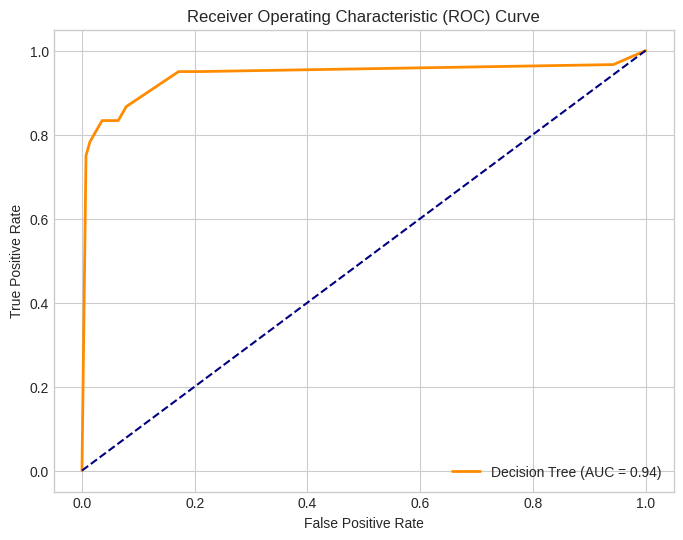

In [ ]:
# Generate predictions
y_pred = pruned_tree.predict(X_test)
y_probs = pruned_tree.predict_proba(X_test)[:, 1]

# Print detailed classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Stay', 'Churn']))

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Decision Tree (AUC = {auc_score:.2f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

# Feature: house area in square feet
X = np.array([
    [500], [600], [700], [800],
    [900], [1000], [1100], [1200],
    [1300], [1400], [1500], [1600],
    [1700], [1800], [1900], [2000]
], dtype=float)

# Target: house price in lakh rupees
y = np.array([
    12, 14, 16, 18,
    20, 22, 24, 27,
    30, 33, 36, 39,
    43, 47, 51, 55
], dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("Actual values:", y_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

print("\nLearned rules:")
print(export_text(model, feature_names=["area"]))

Predictions: [18. 18. 18. 51.]
Actual values: [12. 14. 22. 51.]
MAE: 3.5
MSE: 17.0
R2: 0.9302385226981277

Learned rules:
|--- area <= 1450.00
|   |--- area <= 1000.00
|   |   |--- value: [18.00]
|   |--- area >  1000.00
|   |   |--- area <= 1250.00
|   |   |   |--- value: [25.50]
|   |   |--- area >  1250.00
|   |   |   |--- value: [31.50]
|--- area >  1450.00
|   |--- area <= 1750.00
|   |   |--- value: [39.33]
|   |--- area >  1750.00
|   |   |--- value: [51.00]

